## Importing python libraries

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from shapely.ops import unary_union
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib_scalebar.scalebar import ScaleBar

os.makedirs("output", exist_ok=True)

# Loading four datasets, and projecting

In [10]:
boundary = gpd.read_file("C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/data/chimaliro_boundary.shp")
schools = gpd.read_file("C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/data/Primary_Schools.shp")
protected_areas = gpd.read_file("C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/data/Protected_Areas.shp")
roads = gpd.read_file("C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/data/Roads.shp")


# Checking the projection of the datasets

In [11]:
boundary.crs

<Projected CRS: EPSG:32736>
Name: WGS 84 / UTM zone 36S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, southern hemisphere between 80°S and equator, onshore and offshore. Burundi. Eswatini (Swaziland). Kenya. Malawi. Mozambique. Rwanda. South Africa. Tanzania. Uganda. Zambia. Zimbabwe.
- bounds: (30.0, -80.0, 36.0, 0.0)
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [12]:
schools.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: Arc_1950
- Ellipsoid: Clarke 1880
- Prime Meridian: Greenwich

In [13]:
protected_areas.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: unknown
- Ellipsoid: Unknown
- Prime Meridian: Greenwich

In [14]:
roads.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

# Reprojecting the coordinate system
    -Assign schools crs to all the layers

In [16]:
boundary = boundary.to_crs(schools.crs)

In [17]:
boundary.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: Arc_1950
- Ellipsoid: Clarke 1880
- Prime Meridian: Greenwich

In [18]:
 protected_areas = protected_areas.to_crs(schools.crs)

In [19]:
protected_areas.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: Arc_1950
- Ellipsoid: Clarke 1880
- Prime Meridian: Greenwich

In [20]:
roads = roads.to_crs(schools.crs)

In [21]:
roads.crs

<Projected CRS: PROJCS["UTM_Zone_36_Southern_Hemisphere",GEOGCS["G ...>
Name: UTM_Zone_36_Southern_Hemisphere
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 36S
- method: Transverse Mercator
Datum: Arc_1950
- Ellipsoid: Clarke 1880
- Prime Meridian: Greenwich

In [24]:
chimaliro_boundary = boundary[boundary['TA_NAME'] == 'CHIMALIRO']

In [25]:
chimaliro_boundary

,AREA,PERIMETER,ADMIN_BND_,ADMIN_BND1,TA_NAME,DISTRICT,REGION,NAME_OF_TH,ACRES,HECTARES,geometry
0,284.266,99.008,250,201,CHIMALIRO,THYOLO,SOUTHERN,None,70243.314,28426.574,"POLYGON ((735995.726 8242975.067, 735987.913 8..."


## Plot Chimaliro boundary

<Axes: >

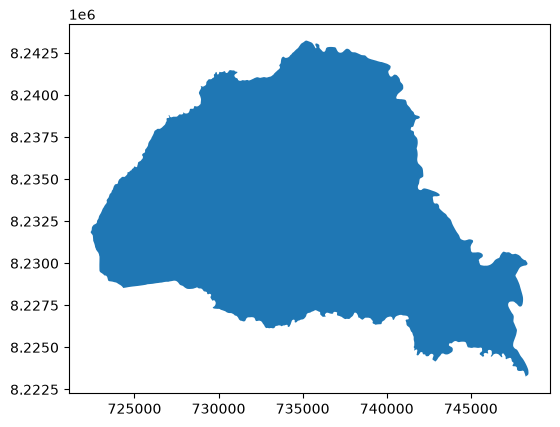

In [26]:
chimaliro_boundary.plot()

## Plot the boundary and overlay the roads

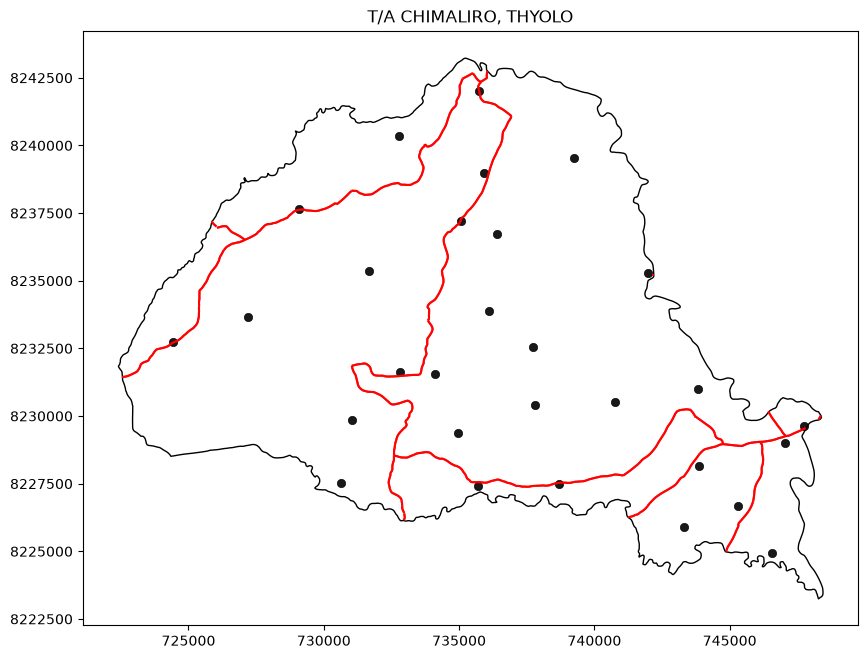

In [28]:
#Clip roads in the boundary
roads_clipped = gpd.clip(roads, chimaliro_boundary)

fig, ax = plt.subplots(figsize=(10, 10))

#plot the base map boundary
chimaliro_boundary.plot(ax=ax, color="white", edgecolor="black")

#overlay schools and roads on top
schools.plot(ax=ax, color="black", linewidth=0.5, alpha=0.9, label="schools")
roads.plot(ax=ax, color="red", linewidth=1.5, alpha=0.9, label="roads")

#title
ax.set_title("T/A CHIMALIRO, THYOLO")

# CRITICAL FIXES FOR READABILITY
#Force the x and y axes to scale equally so the map doesn't compress into a silver
ax.set_aspect('equal')

#Turn off scientific notation on the axes to stop the overlapping "1e6" numbers
ax.ticklabel_format(style='plain', axis='both')


In [29]:
# Create 500m buffer around roads according to the criteria
roads_buff = roads.copy()
roads_buff["geometry"] = roads_buff.buffer(500)

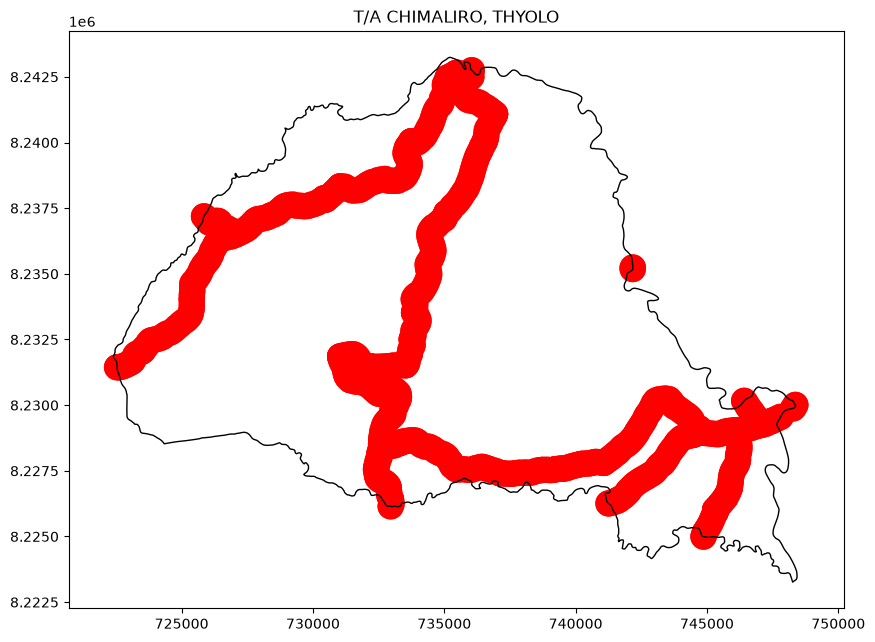

In [30]:
fig, ax = plt.subplots(figsize=(10, 10))

#title
ax.set_title("T/A CHIMALIRO, THYOLO")

# Plot the buffer polygon
roads_buff.plot(ax=ax, color='red', edgecolor='none')

# Plot only the boundary
chimaliro_boundary.boundary.plot(ax=ax, color='black', linewidth=1)

plt.show()

In [31]:
# Create a 2km (2000m) buffer around existing schools
schools_buff = schools.copy()
schools_buff["geometry"] = schools_buff.buffer(2000)

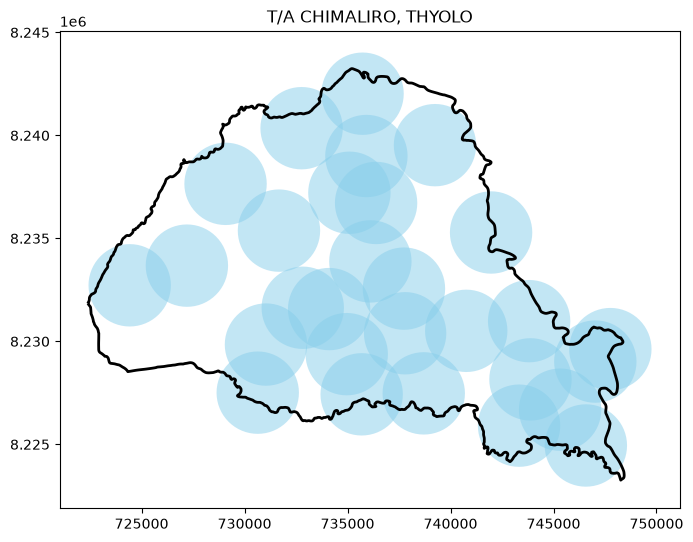

In [32]:

fig, ax = plt.subplots(figsize=(8, 8))

#title
ax.set_title("T/A CHIMALIRO, THYOLO")

# Plot the buffer
schools_buff.plot(ax=ax, color='skyblue', alpha=0.5)

# Plot the Chimaliro boundary
chimaliro_boundary.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2
)

plt.show()

In [33]:
#plot all the buffers
roads_buff.plot(ax = ax, facecolor = "red")
schools_buff.plot(ax = ax, facecolor = "skyblue")

<Axes: title={'center': 'T/A CHIMALIRO, THYOLO'}>

In [34]:
# merge the two GeoDataFrames using union overlay value
merged = schools_buff.overlay(roads_buff, how="union")

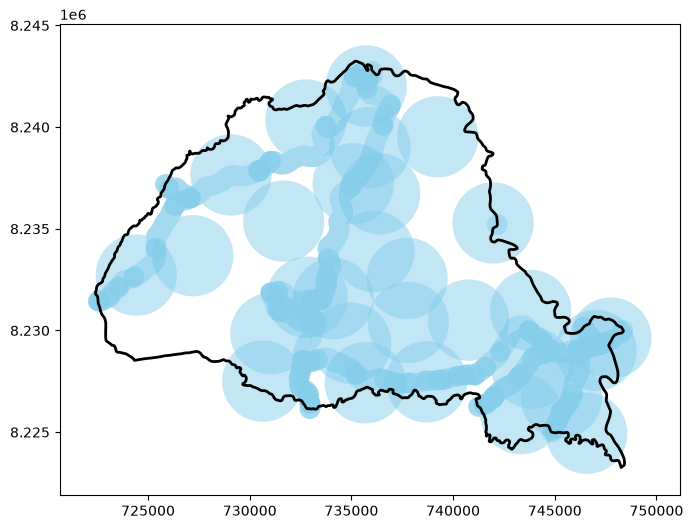

In [35]:
#merged.plot()
fig, ax = plt.subplots(figsize=(8, 8))

# Plot the buffer
merged.plot(ax=ax, color='skyblue', alpha=0.5)

# Plot the Chimaliro boundary
chimaliro_boundary.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2
)

plt.show()

# Merged shapefiles using overlay method and the difference value.

In [36]:
desired_areas = merged.overlay(schools_buff, how = "difference")

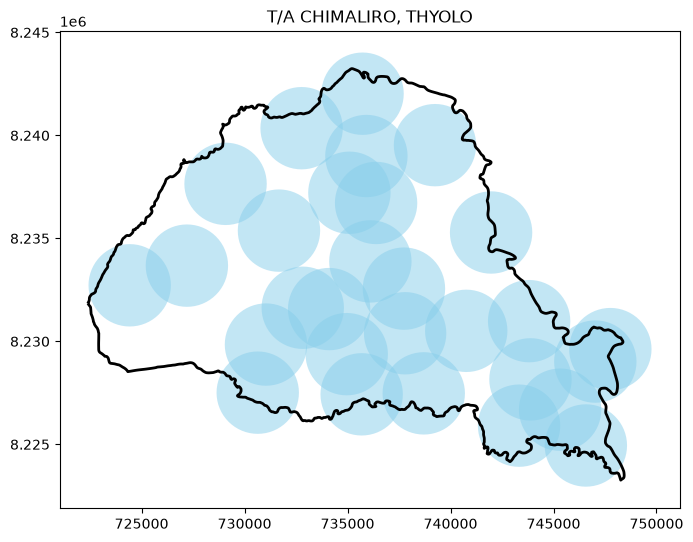

In [37]:
#desired_areas.plot()

fig, ax = plt.subplots(figsize=(8, 8))

#title
ax.set_title("T/A CHIMALIRO, THYOLO")

# Plot the buffer
schools_buff.plot(ax=ax, color='skyblue', alpha=0.5)

# Plot the Chimaliro boundary
chimaliro_boundary.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2
)

plt.show()

In [38]:
final_result = desired_areas[["geometry"]].dissolve()

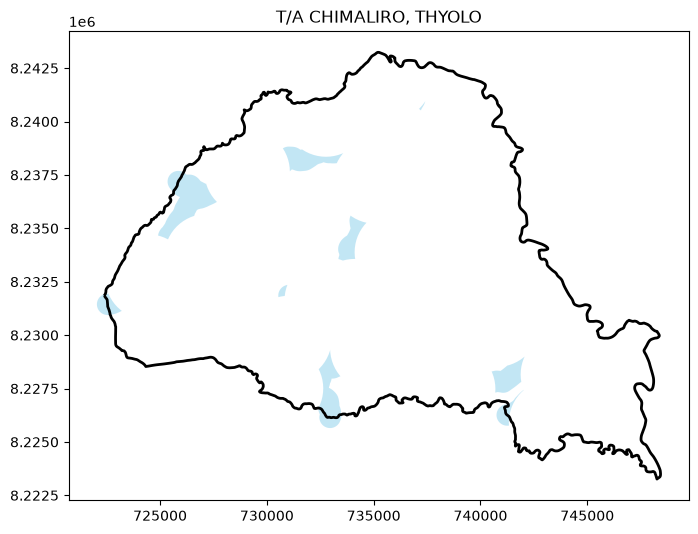

In [39]:
# Plot final result
fig, ax = plt.subplots(figsize=(8, 8))

#title
ax.set_title("T/A CHIMALIRO, THYOLO")

# Plot the buffer
final_result.plot(ax=ax, color='skyblue', alpha=0.5)

# Plot the Chimaliro boundary
chimaliro_boundary.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2
)

plt.show()

In [41]:
# Create an interactive map with satellite imagery
chimaliro_map = final_result.explore(
    name="Final Result",
    popup=True,
    tiles="Esri WorldImagery",
    attr="Esri World Imagery"
)

# Overlay Chimaliro boundary
chimaliro_boundary.explore(
    m=chimaliro_map,
    name="Chimaliro Boundary",
    style_kwds={
        "color": "black",
        "weight": 2,
        "fill": False
    }
)

# Add layer control
folium.LayerControl().add_to(chimaliro_map)

# Save interactive map
chimaliro_map.save("C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/outputs/interactive_map.html")

print("Interactive map saved to outputs/interactive_map.html")

chimaliro_map

Interactive map saved to outputs/interactive_map.html


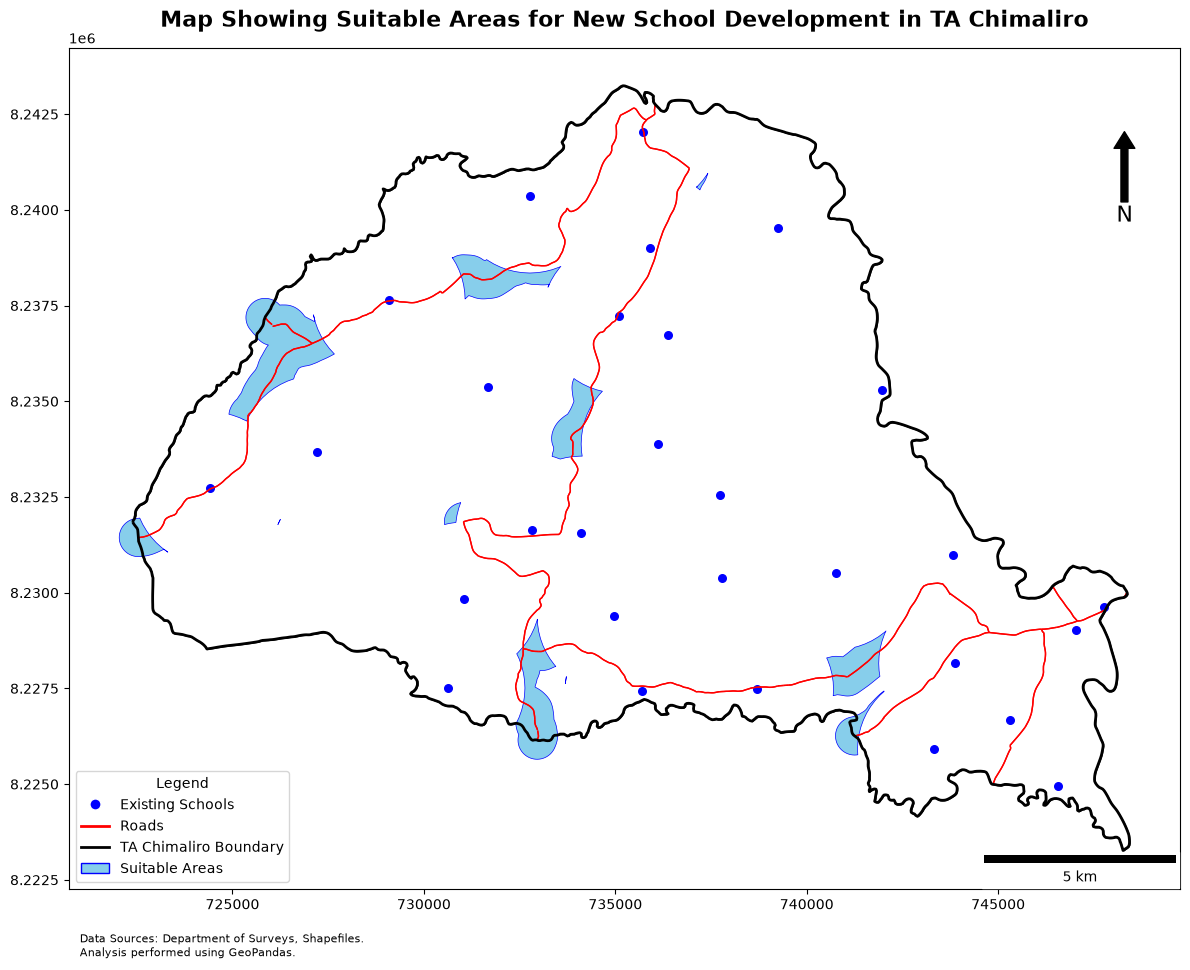

In [42]:
# Create figure
fig, ax = plt.subplots(figsize=(12, 12))

# Plot the map boundary
chimaliro_boundary.plot(
    ax=ax,
    color="white",
    edgecolor="black"
)

# Suitable areas
final_result.plot(
    ax=ax,
    color='skyblue',
    edgecolor='blue',
    linewidth=0.5
)

# Roads
roads.plot(
    ax=ax,
    color='red',
    linewidth=1
)

# Schools
schools.plot(
    ax=ax,
    color='blue',
    markersize=30
)

# TA Boundary
chimaliro_boundary.boundary.plot(
    ax=ax,
    color='black',
    linewidth=2
)

# Title
ax.set_title(
    "Map Showing Suitable Areas for New School Development in TA Chimaliro",
    fontsize=16,
    weight='bold',
    pad=15
)

# Legend
legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='blue',
        markersize=8,
        label='Existing Schools'
    ),

    Line2D(
        [0], [0],
        color='red',
        lw=2,
        label='Roads'
    ),

    Line2D(
        [0], [0],
        color='black',
        lw=2,
        label='TA Chimaliro Boundary'
    ),

    Patch(
        facecolor='skyblue',
        edgecolor='blue',
        label='Suitable Areas'
    )
]

ax.legend(
    handles=legend_elements,
    loc='lower left',
    title='Legend'
)

# Scale bar
scalebar = ScaleBar(
    dx=1,
    location='lower right'
)

ax.add_artist(scalebar)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.90),
    xytext=(0.95, 0.80),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    va='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# Data Sources
ax.text(
    0.01,
    -0.08,
    "Data Sources: Department of Surveys, Shapefiles.\n"
    "Analysis performed using GeoPandas.",
    transform=ax.transAxes,
    fontsize=8
)

# Plot axes
ax.axis('on')

# Tight layout
plt.tight_layout()

# Create output folder if it does not exist
import os
os.makedirs("outputs", exist_ok=True)

# Save outputs
plt.savefig(
    "C:/Users/Lenovo L14 Gen2/Documents/must/geo_information/coding/chimaliro-school-site-accessibility1/outputs/chimaliro_suitability_map.pdf",
    dpi=300,
    bbox_inches='tight'
)

plt.show()